# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [14]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER* :I used a line graph to show how population changed over time. Every line starts at 100 so we can compare them fairly. Africa’s line goes up the most. By 2022, Africa had almost four times as many people as in 1970.

In [15]:
blue = "#0072B2"
grey = "#B6BFC7"

palette = {
    "Africa": blue,
    "Asia": "#E69F00",
    "Europe": "#CC79A7",
    "North America": "#666666",
    "Oceania": "#56B4E9",
    "South America": "#882255",
}

px.defaults.template = "plotly_white"

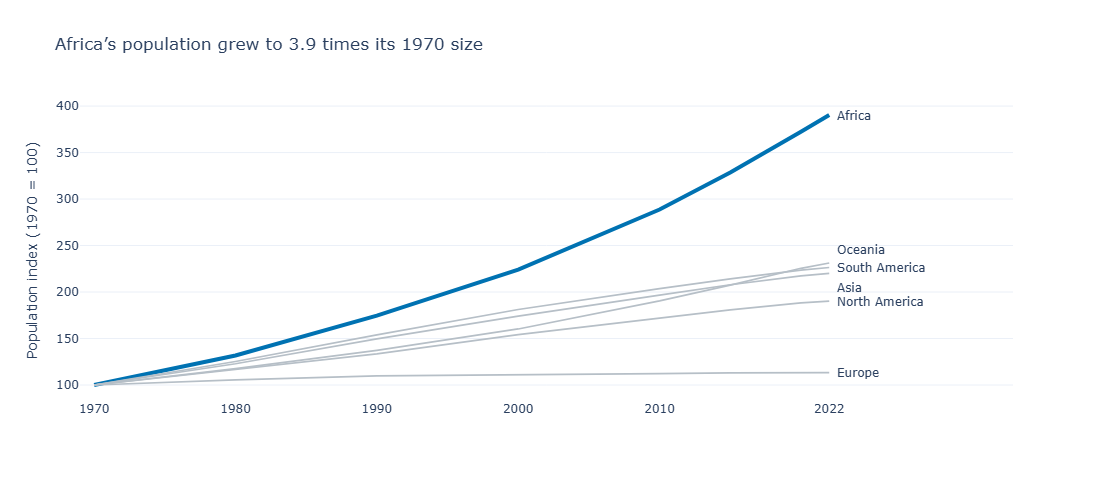

In [16]:
# Q1
# Q1 — Relative population growth since 1970
totals = (
    df_long.groupby(["Continent", "Year"], as_index=False)["Population"]
    .sum()
    .sort_values(["Continent", "Year"])
)
baseline = totals.groupby("Continent")["Population"].transform("first")
totals["Index"] = 100 * totals["Population"] / baseline

fig = px.line(
    totals, x="Year", y="Index", color="Continent",
    labels={"Index": "Population index (1970 = 100)"},
    title="Africa’s population grew to 3.9 times its 1970 size",
    hover_data={"Index": ":.1f", "Population": ":,.0f"},
)
label_shifts = {"Oceania": 14, "Asia": -14}
for trace in fig.data:
    highlight = trace.name == "Africa"
    trace.update(line=dict(color=blue if highlight else grey, width=4 if highlight else 1.7))
    fig.add_annotation(
        x=2022, y=trace.y[-1], text=trace.name, showarrow=False,
        xanchor="left", xshift=6, yshift=label_shifts.get(trace.name, 0),
    )

fig.update_xaxes(title=None, showgrid=False, range=[1969, 2035],
                 tickvals=[1970, 1980, 1990, 2000, 2010, 2022])
fig.update_layout(showlegend=False, height=480)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER*-I used bars to show which countries added the most people. A longer bar means more people were added. India has the longest bar. The four blue bars are Nigeria, Ethiopia, DR Congo and Egypt, all in Africa.

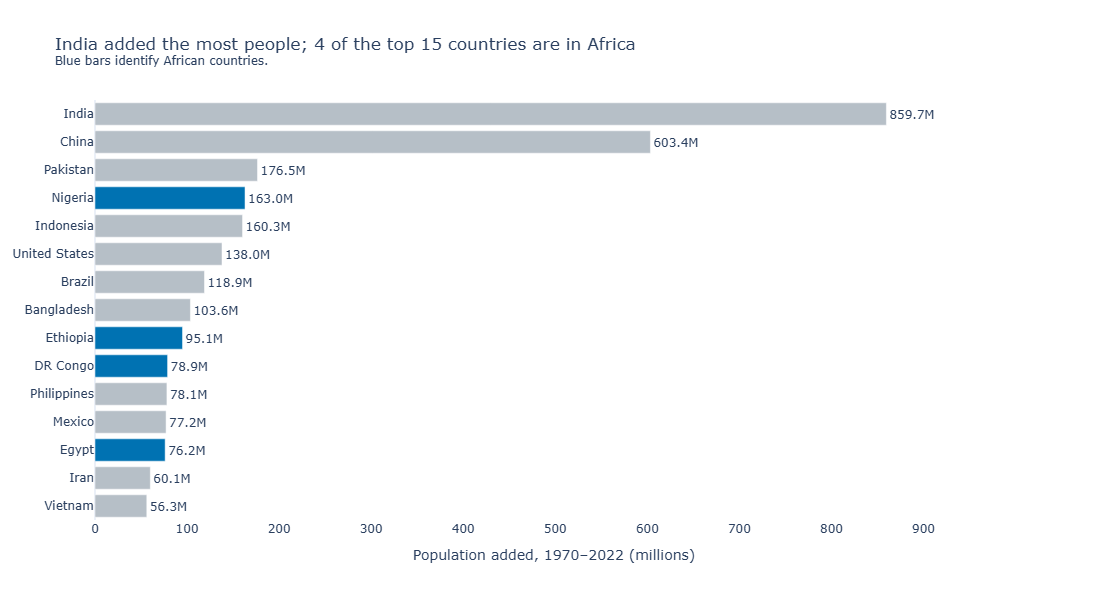

In [17]:
# Q2
# Q2 — Top 15 countries by absolute population gain
growth = df.assign(Added=df["2022 Population"] - df["1970 Population"])
top = growth.nlargest(15, "Added").copy()
top["Millions"] = top["Added"] / 1_000_000
africa_count = top["Continent"].eq("Africa").sum()

fig = px.bar(
    top, x="Millions", y="Country", orientation="h", text="Millions",
    custom_data=["Continent", "Added"],
    labels={"Millions": "Population added, 1970–2022 (millions)"},
    title=f"India added the most people; {africa_count} of the top 15 countries are in Africa"
          "<br><sup>Blue bars identify African countries.</sup>",
)
fig.update_traces(
    marker_color=np.where(top["Continent"].eq("Africa"), blue, grey),
    texttemplate="%{text:.1f}M", textposition="outside",
    hovertemplate="%{y} · %{customdata[0]}<br>%{customdata[1]:,.0f} people added<extra></extra>",
)
fig.update_yaxes(title=None, categoryorder="array", categoryarray=top["Country"].tolist()[::-1])
fig.update_xaxes(range=[0, top["Millions"].max() * 1.16], showgrid=False)
fig.update_layout(height=600)
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER* - Scatter plot. Each dot is a country. Dots farther right mean more land, and dots higher up mean more people. I used this graph to see whether bigger countries usually have more people. Many do, but Mongolia has much more land than Bangladesh and far fewer people.

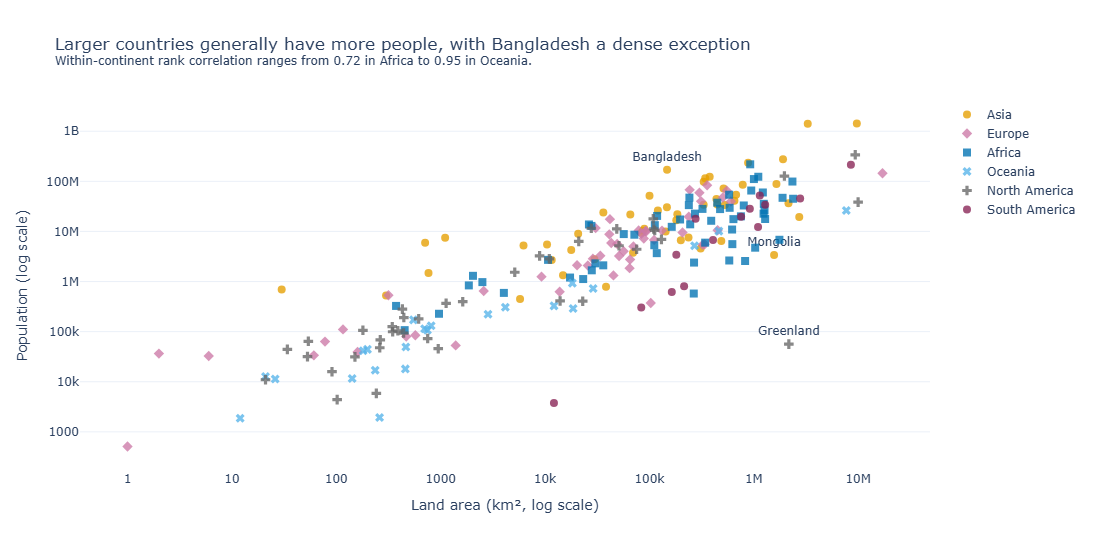

In [18]:
# Q3
# YOUR CODE HERE
# Q3 — Land area and population by continent
points = df.copy()
examples = ["Bangladesh", "Mongolia", "Greenland"]
points["Label"] = points["Country"].where(points["Country"].isin(examples), "")

# Spearman correlation compares the ranks of area and population within each continent.
rho = {
    continent: group["Area"].rank().corr(group["2022 Population"].rank())
    for continent, group in points.groupby("Continent")
}

fig = px.scatter(
    points, x="Area", y="2022 Population", log_x=True, log_y=True,
    color="Continent", symbol="Continent", color_discrete_map=palette,
    text="Label", hover_name="Country", hover_data={"Label": False},
    labels={"Area": "Land area (km², log scale)", "2022 Population": "Population (log scale)"},
    title="Larger countries generally have more people, with Bangladesh a dense exception"
          f"<br><sup>Within-continent rank correlation ranges from {min(rho.values()):.2f} "
          f"in {min(rho, key=rho.get)} to {max(rho.values()):.2f} in {max(rho, key=rho.get)}.</sup>",
)
fig.update_traces(marker_size=8, marker_opacity=0.78, textposition="top center")
fig.update_xaxes(showgrid=False)
fig.update_layout(height=550, legend_title_text=None)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER* - I used one box for each continent to show how crowded its countries are. The line inside each box shows the middle value. North America has the highest middle value, at about 221 people per km². South America has the lowest, at about 18

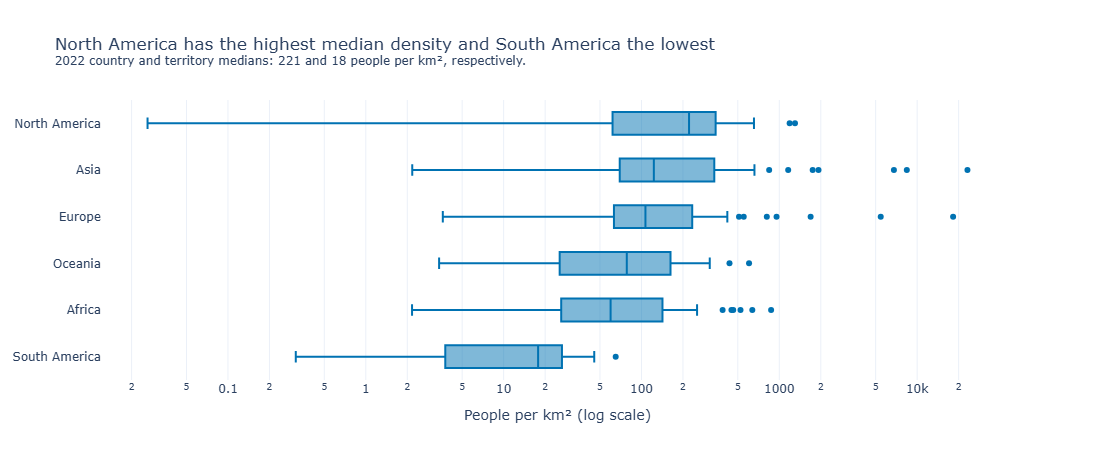

In [19]:
# Q4
# YOUR CODE HERE
# Q4 — Distribution of country and territory densities within continents
medians = df.groupby("Continent")["Density"].median().sort_values(ascending=False)

fig = px.box(
    df, x="Density", y="Continent", orientation="h", log_x=True,
    points="outliers", hover_name="Country",
    category_orders={"Continent": medians.index.tolist()},
    color_discrete_sequence=[blue],
    labels={"Density": "People per km² (log scale)"},
    title="North America has the highest median density and South America the lowest"
          "<br><sup>2022 country and territory medians: 221 and 18 people per km², respectively.</sup>",
)
fig.update_yaxes(title=None, showgrid=False)
fig.update_layout(height=460)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER* -I used a map so we can see where populations changed. Blue means a place gained people. Orange means it lost people. Of the 34 countries and territories that lost people, 18 were in Europe.

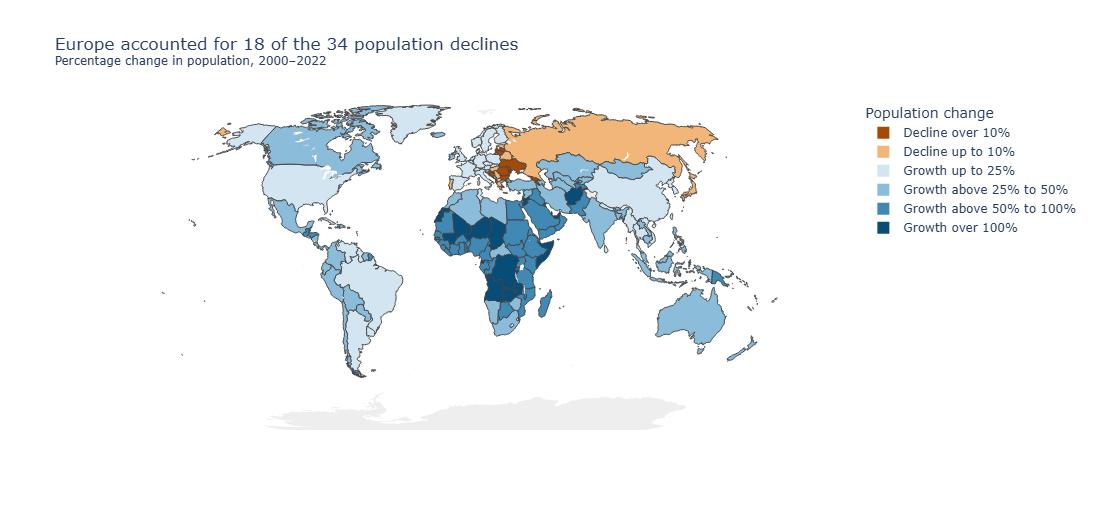

In [20]:
# Q5
# YOUR CODE HERE
change = df.copy()
# Q5 — Geographic pattern of population growth and decline
change = df.copy()
change["Change (%)"] = 100 * (change["2022 Population"] / change["2000 Population"] - 1)
pct = change["Change (%)"]

bands = [
    "Decline over 10%", "Decline up to 10%", "No change",
    "Growth up to 25%", "Growth above 25% to 50%",
    "Growth above 50% to 100%", "Growth over 100%",
]
change["Change band"] = np.select(
    [pct < -10, pct < 0, pct == 0, pct <= 25, pct <= 50, pct <= 100],
    bands[:-1], default=bands[-1],
)
colors = dict(zip(bands, ["#A44A06", "#F2B679", "#EEEEEE", "#D3E5F0",
                          "#8BBCD9", "#4089B4", "#084C78"]))
declines = change.loc[pct < 0]
europe_declines = declines["Continent"].eq("Europe").sum()

fig = px.choropleth(
    change, locations="CCA3", locationmode="ISO-3", color="Change band",
    color_discrete_map=colors, category_orders={"Change band": bands},
    hover_name="Country", hover_data={"Change (%)": ":.1f", "CCA3": False},
    projection="natural earth",
    title=f"Europe accounted for {europe_declines} of the {len(declines)} population declines"
          "<br><sup>Percentage change in population, 2000–2022</sup>",
)
fig.update_geos(showframe=False, showcoastlines=False, showland=True, landcolor="#EEEEEE")
fig.update_layout(height=510, legend_title_text="Population change")
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER* -Each country is a box inside its continent. A bigger box means more people live there. Asia takes up the most space because about 6 out of every 10 people in the world lived there in 2022

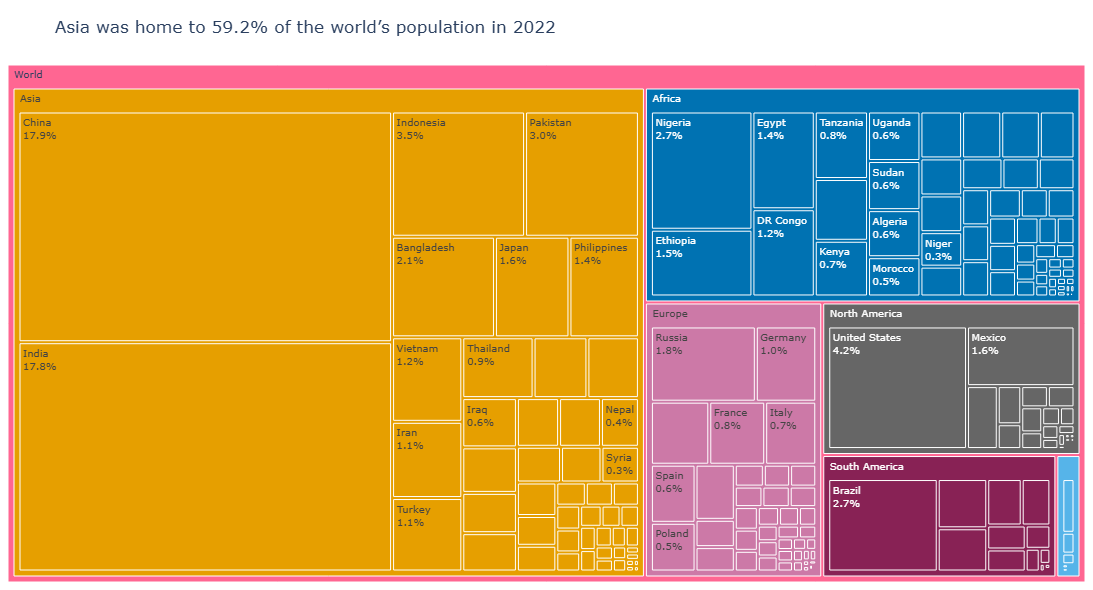

In [21]:
# Q6
# YOUR CODE HERE
# Q6 — World population by continent and country
fig = px.treemap(
    df, path=[px.Constant("World"), "Continent", "Country"],
    values="2022 Population", color="Continent", color_discrete_map=palette,
    title="Asia was home to 59.2% of the world’s population in 2022",
)
fig.update_traces(
    root_color="#E8EBEE", marker_line_width=1,
    texttemplate="%{label}<br>%{percentRoot:.1%}",
    hovertemplate="%{label}<br>Population: %{value:,.0f}"
                  "<br>Share of world population: %{percentRoot:.2%}<extra></extra>",
)
fig.update_layout(height=590, margin=dict(t=65, l=8, r=8, b=8),
                  uniformtext=dict(minsize=10, mode="hide"))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*ANSWER*  - 100% stacked bar graph. Each bar shows how the world’s people were divided among the groups in one year. Imagine the world had just 100 people: about 10 out of 100 lived in Africa in 1970, compared with 18 out of 100 in 2022.

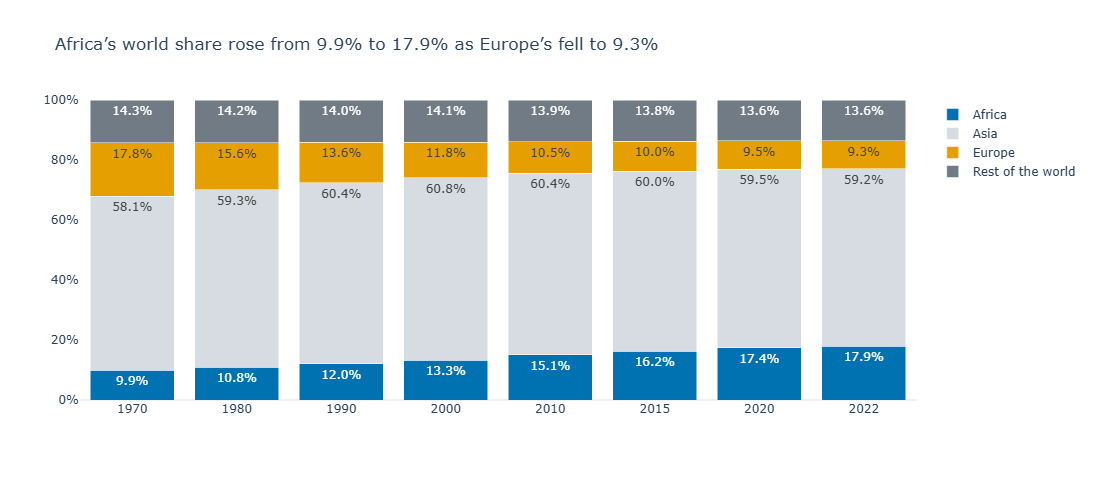

In [22]:
# Q7 — Changes in each group's share of world population
groups = df_long.copy()
groups["Group"] = groups["Continent"].where(
    groups["Continent"].isin(["Africa", "Asia", "Europe"]), "Rest of the world"
)
shares = groups.groupby(["Year", "Group"], as_index=False)["Population"].sum()
world_total = shares.groupby("Year")["Population"].transform("sum")
shares["Share"] = shares["Population"] / world_total
shares["Year"] = shares["Year"].astype(str)

fig = px.bar(
    shares, x="Year", y="Share", color="Group", text="Share", barmode="stack",
    category_orders={
        "Group": ["Africa", "Asia", "Europe", "Rest of the world"],
        "Year": sorted(shares["Year"].unique()),
    },
    color_discrete_map={
        "Africa": blue, "Asia": "#D6DCE1",
        "Europe": "#E69F00", "Rest of the world": "#707B85",
    },
    title="Africa’s world share rose from 9.9% to 17.9% as Europe’s fell to 9.3%",
)
fig.update_traces(
    texttemplate="%{text:.1%}", textposition="inside",
    hovertemplate="%{fullData.name} · %{x}<br>World share: %{y:.2%}<extra></extra>",
)
fig.update_yaxes(title=None, range=[0, 1], tickformat=".0%", showgrid=False)
fig.update_xaxes(type="category", title=None, showgrid=False)
fig.update_layout(height=480, legend_title_text=None)
fig.show()